<a href="https://colab.research.google.com/github/saraalmazroa/-IT326-DataMining-Project-/blob/main/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Phase 3**

In [1]:
# Load libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn import tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Load data
url = "https://raw.githubusercontent.com/saraalmazroa/-IT326-DataMining-Project-/main/Dataset/Preprocessed_data.csv"
df = pd.read_csv(url, index_col=0)   # index_col=0 removes the extra "Unnamed: 0" column
print(df.head())   # get the first 5 rows

                 Age     Sex  Job Housing Saving accounts Checking account  \
Unnamed: 0                                                                   
0           1.000000    male    2     own          little           little   
1           0.065934  female    2     own          little         moderate   
2           0.659341    male    1     own          little           little   
3           0.571429    male    2    free          little           little   
4           0.747253    male    2    free          little           little   

            Credit amount  Duration              Purpose  Risk  \
Unnamed: 0                                                       
0                0.120408  0.052632             radio/TV  good   
1                0.746950  1.000000             radio/TV   bad   
2                0.241864  0.210526            education  good   
3                0.999951  1.000000  furniture/equipment  good   
4                0.605316  0.526316                  car 

## Classification – Gini Index: 90% training / 10% testing

In [3]:
# Feature Selection: split dataset in features and target variable
# If you have an ID column you should drop it before the training process
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set
X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(X, y, test_size=0.1, random_state=1)   # 90% training and 10% test

# Create Decision Tree classifier object (default criterion is Gini)
clf_90 = DecisionTreeClassifier(criterion="gini", random_state=1)

# Train Decision Tree Classifier
clf_90 = clf_90.fit(X_train_90, y_train_90)

# Predict the response for test dataset
y_pred_90 = clf_90.predict(X_test_90)

# Model Accuracy, how often is the classifier correct?
acc_90 = metrics.accuracy_score(y_test_90, y_pred_90)
print("Accuracy:", acc_90)

Accuracy: 0.64


### Confusion matrix (90/10)


[[13 17]
 [19 51]]


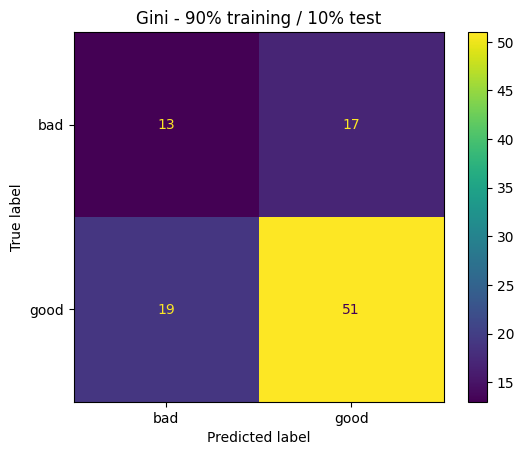

In [4]:
# Compute and print the confusion matrix
cm_90 = confusion_matrix(y_test_90, y_pred_90)
print(cm_90)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_90, X_test_90, y_test_90, display_labels=cn)
plt.title("Gini - 90% training / 10% test")
plt.show()

### Decision tree plot (90/10)


Accuracy of the pruned tree (for the plot only): 0.7


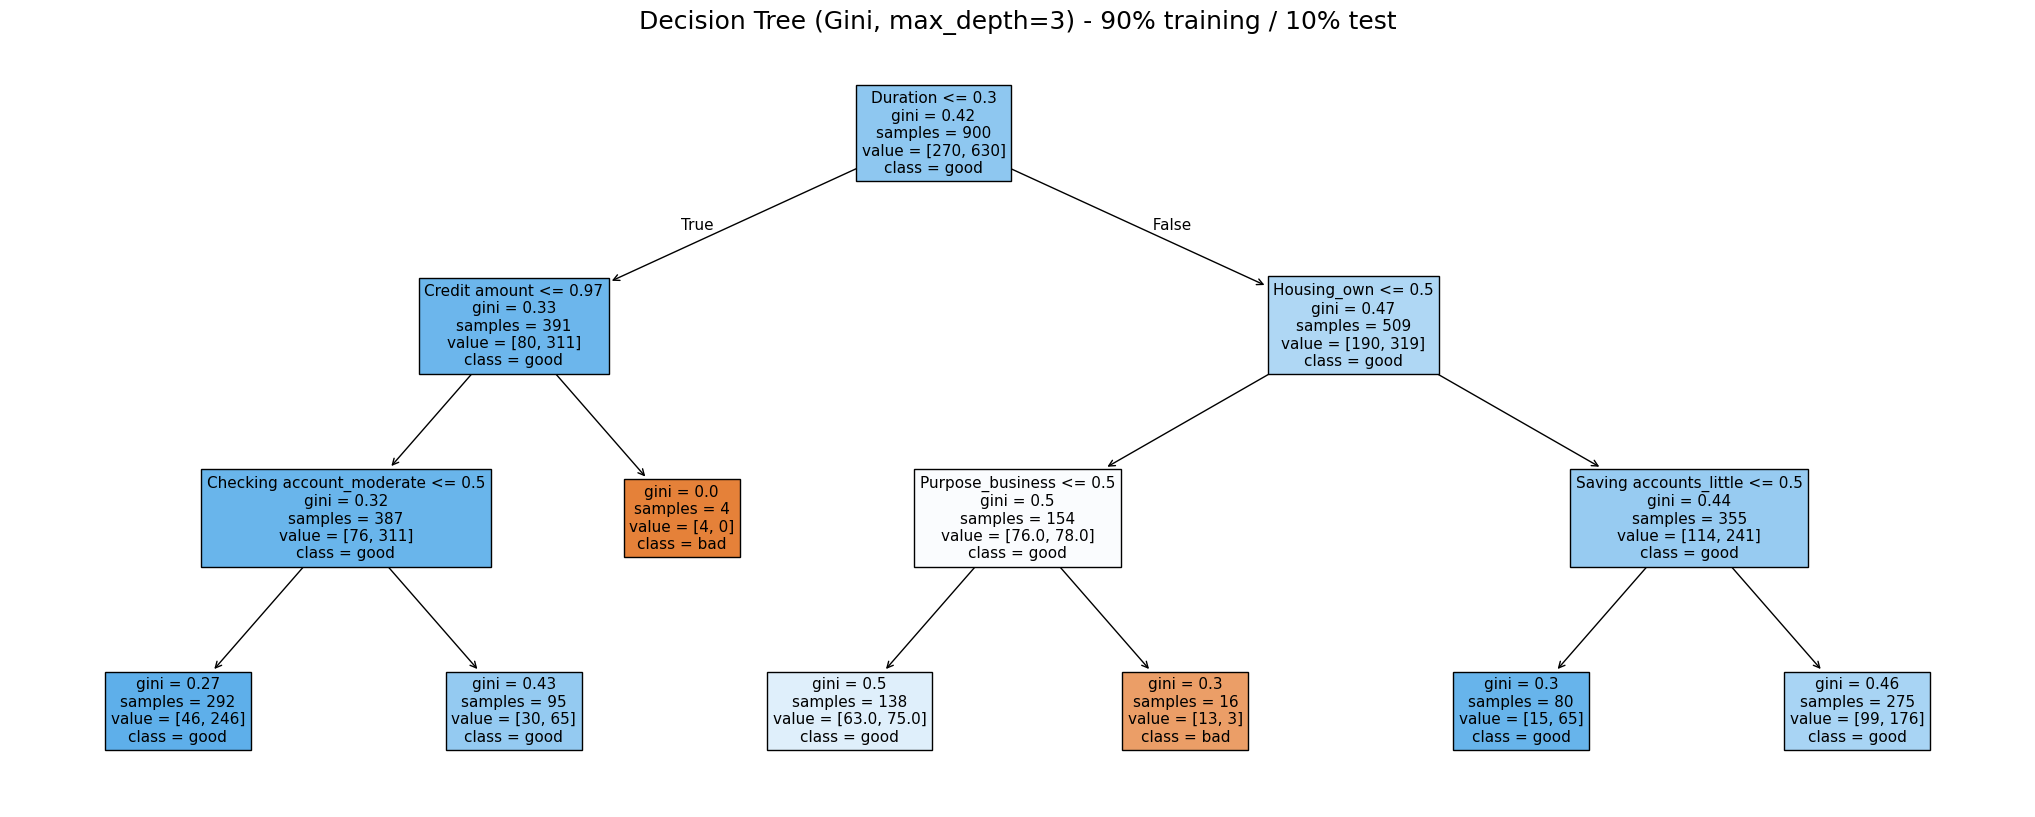

In [5]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_90_plot = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1)
clf_90_plot = clf_90_plot.fit(X_train_90, y_train_90)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_90, clf_90_plot.predict(X_test_90)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_90_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Gini, max_depth=3) - 90% training / 10% test", fontsize=18)
fig.savefig('gini_DT_90_10.png', dpi=300, bbox_inches='tight')   # You can save your plot if you want
plt.show()

## Classification – Gini Index: 80% training / 20% testing


In [6]:
# Feature Selection: split dataset in features and target variable
# If you have an ID column you should drop it before the training process
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(X, y, test_size=0.2, random_state=1)   # 80% training and 20% test

# Create Decision Tree classifier object (default criterion is Gini)
clf_80 = DecisionTreeClassifier(criterion="gini", random_state=1)

# Train Decision Tree Classifier
clf_80 = clf_80.fit(X_train_80, y_train_80)

# Predict the response for test dataset
y_pred_80 = clf_80.predict(X_test_80)

# Model Accuracy, how often is the classifier correct?
acc_80 = metrics.accuracy_score(y_test_80, y_pred_80)
print("Accuracy:", acc_80)

Accuracy: 0.66


### Confusion matrix (80/20)


[[ 26  33]
 [ 35 106]]


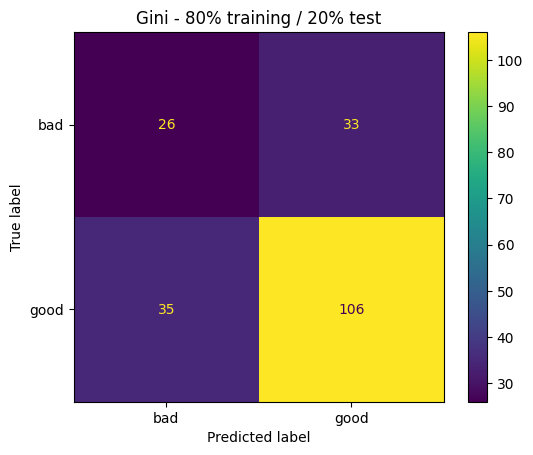

In [7]:
# Compute and print the confusion matrix
cm_80 = confusion_matrix(y_test_80, y_pred_80)
print(cm_80)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_80, X_test_80, y_test_80, display_labels=cn)
plt.title("Gini - 80% training / 20% test")
plt.show()

### Decision tree plot (80/20)


Accuracy of the pruned tree (for the plot only): 0.71


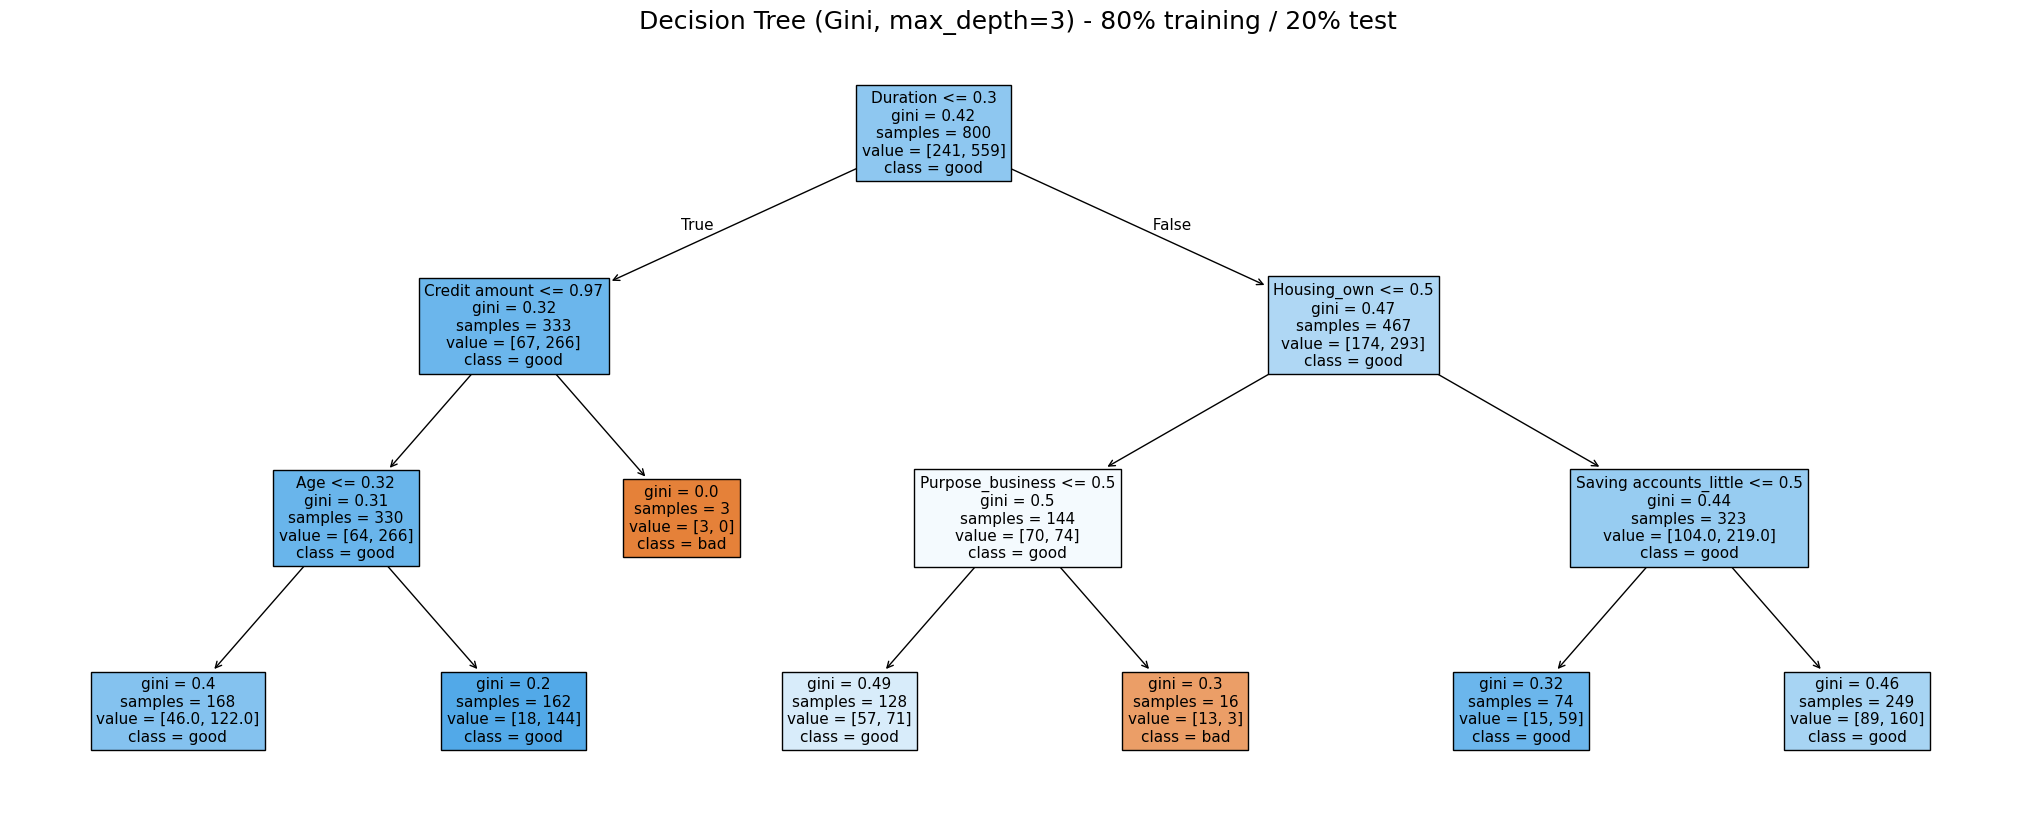

In [8]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_80_plot = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1)
clf_80_plot = clf_80_plot.fit(X_train_80, y_train_80)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_80, clf_80_plot.predict(X_test_80)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_80_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Gini, max_depth=3) - 80% training / 20% test", fontsize=18)
fig.savefig('gini_DT_80_20.png', dpi=300, bbox_inches='tight')   # You can save your plot if you want
plt.show()

## Classification – Gini Index: 70% training / 30% testing


In [9]:
# Feature Selection: split dataset in features and target variable
# If you have an ID column you should drop it before the training process
X = df.drop(columns=["Risk"])   # Features: all columns except the class label
y = df["Risk"]                  # Target variable: the class label (good / bad)

# scikit-learn accepts only numerical data, so encode the categorical columns of X (not the target)
X = pd.get_dummies(X)

fn = X.columns.tolist()   # feature names after encoding
cn = [str(c) for c in sorted(y.unique())]   # class names

# Split dataset into training set and test set
X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(X, y, test_size=0.3, random_state=1)   # 70% training and 30% test

# Create Decision Tree classifier object (default criterion is Gini)
clf_70 = DecisionTreeClassifier(criterion="gini", random_state=1)

# Train Decision Tree Classifier
clf_70 = clf_70.fit(X_train_70, y_train_70)

# Predict the response for test dataset
y_pred_70 = clf_70.predict(X_test_70)

# Model Accuracy, how often is the classifier correct?
acc_70 = metrics.accuracy_score(y_test_70, y_pred_70)
print("Accuracy:", acc_70)

Accuracy: 0.6233333333333333


### Confusion matrix (70/30)


[[ 34  52]
 [ 61 153]]


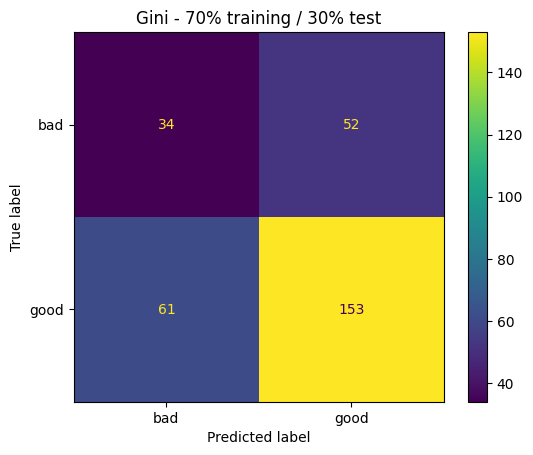

In [10]:
# Compute and print the confusion matrix
cm_70 = confusion_matrix(y_test_70, y_pred_70)
print(cm_70)

# Create a confusion matrix display object
disp = ConfusionMatrixDisplay.from_estimator(clf_70, X_test_70, y_test_70, display_labels=cn)
plt.title("Gini - 70% training / 30% test")
plt.show()

### Decision tree plot (70/30)


Accuracy of the pruned tree (for the plot only): 0.7


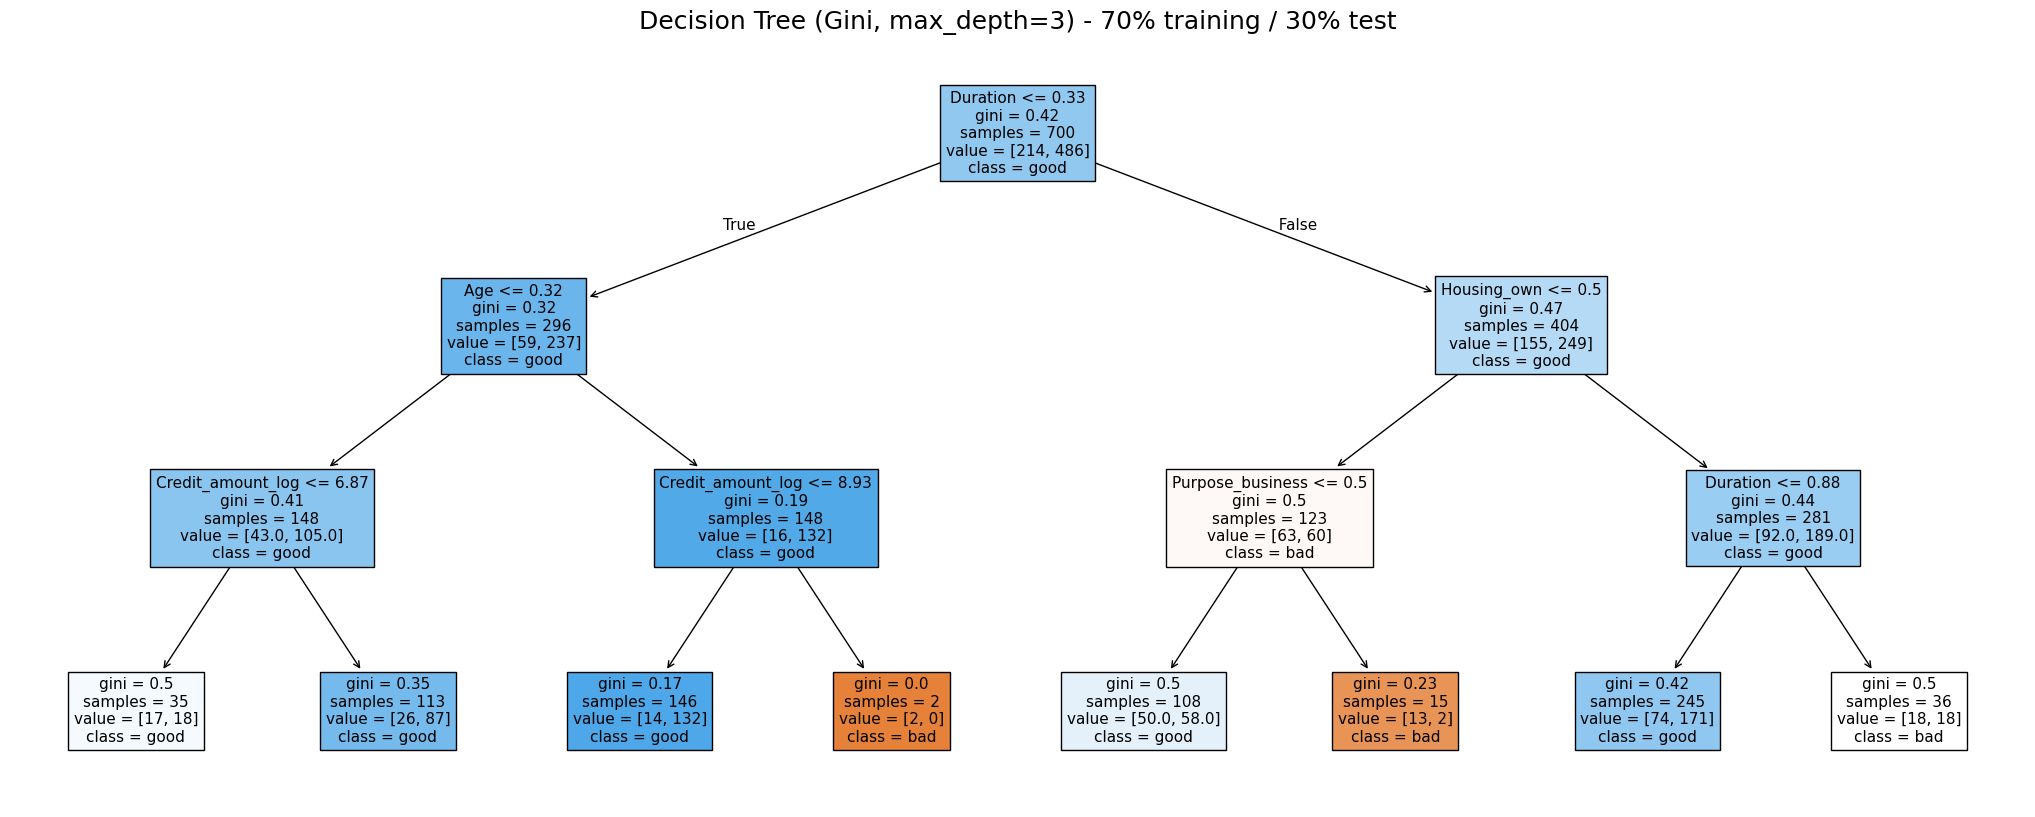

In [11]:
# Build a pruned tree (max_depth=3) only for visualization, so every branch ends in a leaf with a class label
clf_70_plot = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=1)
clf_70_plot = clf_70_plot.fit(X_train_70, y_train_70)
print("Accuracy of the pruned tree (for the plot only):", metrics.accuracy_score(y_test_70, clf_70_plot.predict(X_test_70)))

# Setting dpi to make the image clearer than default
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf_70_plot,
               feature_names=fn,
               class_names=cn,
               filled=True,
               fontsize=11,
               precision=2);

plt.title("Decision Tree (Gini, max_depth=3) - 70% training / 30% test", fontsize=18)
fig.savefig('gini_DT_70_30.png', dpi=300, bbox_inches='tight')   # You can save your plot if you want
plt.show()

### Gini index – accuracy summary table


In [12]:
gini_table = pd.DataFrame(
    [[round(acc_90, 4), round(acc_80, 4), round(acc_70, 4)]],
    index=["Accuracy"],
    columns=["90% training set 10% testing set",
             "80% training set 20% testing set",
             "70% training set 30% testing set"])
gini_table

,90% training set 10% testing set,80% training set 20% testing set,70% training set 30% testing set
Accuracy,0.64,0.66,0.6233
